# E-Commerce Revenue Leakage & Profitability Analysis

## Exploratory Data Analysis (EDA)

### Objective

The purpose of this analysis is to identify where the business is losing revenue and profit across discounts, returns, cancellations, shipping costs, products, regions, customer segments, and delivery performance.

This analysis uses a synthetic e-commerce dataset and does not represent any real company or customer data.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

In [2]:
file_path = "../data/ecommerce_revenue_leakage_cleaned.csv"
df = pd.read_csv(file_path,parse_dates=["order_date"])
print("Dataset loaded successfully.")
print("Shape:", df.shape)

Dataset loaded successfully.
Shape: (100000, 31)


In [3]:
total_orders = len(df)

gross_revenue = df["gross_revenue"].sum()
net_revenue = df["net_revenue"].sum()
net_profit = df["net_profit"].sum()
total_leakage = df["revenue_leakage"].sum()

total_discount = df["discount_amount"].sum()
total_return_loss = df["return_loss"].sum()
total_cancellation_loss = df["cancellation_loss"].sum()
total_shipping_cost = df["shipping_cost"].sum()

returned_orders = (df["order_status"] == "Returned").sum()
cancelled_orders = (df["order_status"] == "Cancelled").sum()

return_rate = returned_orders / total_orders * 100
cancellation_rate = cancelled_orders / total_orders * 100

profit_margin = (
    net_profit / net_revenue * 100
    if net_revenue != 0
    else 0
)
average_order_value = (
    net_revenue / total_orders
)

In [4]:
print("CORE BUSINESS KPIs")
print("-----------------------------")

print(f"Total Orders: {total_orders:,}")
print(f"Gross Revenue: ₹{gross_revenue:,.2f}")
print(f"Net Revenue: ₹{net_revenue:,.2f}")
print(f"Net Profit: ₹{net_profit:,.2f}")
print(f"Overall Profit Margin: {profit_margin:.2f}%")

print(f"\nTotal Revenue Leakage: ₹{total_leakage:,.2f}")
print(f"Total Discount Amount: ₹{total_discount:,.2f}")
print(f"Total Return Loss: ₹{total_return_loss:,.2f}")
print(f"Total Cancellation Loss: ₹{total_cancellation_loss:,.2f}")
print(f"Total Shipping Cost: ₹{total_shipping_cost:,.2f}")

print(f"\nReturned Orders: {returned_orders:,}")
print(f"Return Rate: {return_rate:.2f}%")

print(f"Cancelled Orders: {cancelled_orders:,}")
print(f"Cancellation Rate: {cancellation_rate:.2f}%")

print(f"\nAverage Order Value: ₹{average_order_value:,.2f}")

CORE BUSINESS KPIs
-----------------------------
Total Orders: 100,000
Gross Revenue: ₹1,978,786,652.20
Net Revenue: ₹1,493,569,049.16
Net Profit: ₹175,934,304.81
Overall Profit Margin: 11.78%

Total Revenue Leakage: ₹455,020,701.84
Total Discount Amount: ₹303,652,720.74
Total Return Loss: ₹129,704,397.14
Total Cancellation Loss: ₹636,573.25
Total Shipping Cost: ₹21,027,010.72

Returned Orders: 8,133
Return Rate: 8.13%
Cancelled Orders: 3,223
Cancellation Rate: 3.22%

Average Order Value: ₹14,935.69


## 5.2 Revenue Leakage by Reason

This section analyzes the major sources of revenue leakage and identifies which business issues contribute the most to total leakage.

In [5]:
leakage_summary = (
    df.groupby("leakage_reason")
      .agg(
          orders=("order_id", "count"),
          total_leakage=("revenue_leakage", "sum"),
          total_net_profit=("net_profit", "sum")
      )
      .reset_index()
)

leakage_summary["order_pct"] = (
    leakage_summary["orders"] / len(df) * 100
)

leakage_summary["leakage_pct"] = (
    leakage_summary["total_leakage"]
    / df["revenue_leakage"].sum()
    * 100
)

leakage_summary = leakage_summary.sort_values(
    "total_leakage",
    ascending=False
)

leakage_summary

,leakage_reason,orders,total_leakage,total_net_profit,order_pct,leakage_pct
4,Low-Margin Product,15187,"174,152,670.95","-25,130,994.13",15.19,38.27
5,Return Loss,8133,"156,341,632.04","-1,714,366.70",8.13,34.36
2,Healthy Order,57140,"74,997,769.57","148,442,919.74",57.14,16.48
3,High Shipping Cost,10130,"24,963,431.87","50,662,565.44",10.13,5.49
1,Excessive Discount,6187,"12,801,200.46","4,990,624.63",6.19,2.81
0,Cancellation Loss,3223,"11,763,996.95","-1,316,444.17",3.22,2.59


In [6]:
display_leakage = leakage_summary.copy()

display_leakage["total_leakage"] = (
    display_leakage["total_leakage"].round(2)
)

display_leakage["total_net_profit"] = (
    display_leakage["total_net_profit"].round(2)
)

display_leakage["order_pct"] = (
    display_leakage["order_pct"].round(2)
)

display_leakage["leakage_pct"] = (
    display_leakage["leakage_pct"].round(2)
)

display_leakage

,leakage_reason,orders,total_leakage,total_net_profit,order_pct,leakage_pct
4,Low-Margin Product,15187,"174,152,670.95","-25,130,994.13",15.19,38.27
5,Return Loss,8133,"156,341,632.04","-1,714,366.70",8.13,34.36
2,Healthy Order,57140,"74,997,769.57","148,442,919.74",57.14,16.48
3,High Shipping Cost,10130,"24,963,431.87","50,662,565.44",10.13,5.49
1,Excessive Discount,6187,"12,801,200.46","4,990,624.63",6.19,2.81
0,Cancellation Loss,3223,"11,763,996.95","-1,316,444.17",3.22,2.59


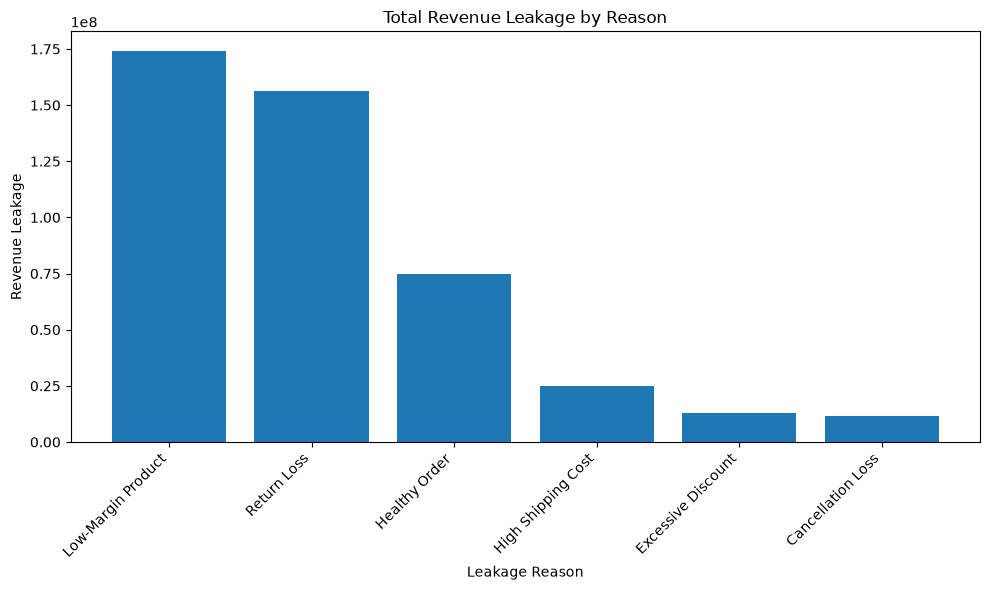

In [7]:
plt.figure(figsize=(10, 6))

plt.bar(
    leakage_summary["leakage_reason"],
    leakage_summary["total_leakage"]
)

plt.title("Total Revenue Leakage by Reason")
plt.xlabel("Leakage Reason")
plt.ylabel("Revenue Leakage")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [8]:
print(
    "Total Leakage Contribution:",
    round(leakage_summary["leakage_pct"].sum(), 2),
    "%"
)

Total Leakage Contribution: 100.0 %


## 5.3 Discount Impact on Profitability

This section analyzes how different discount levels affect revenue, profit, profit margin, and revenue leakage.

The objective is to determine whether higher discount levels are associated with weaker profitability.

In [9]:
discount_analysis = (
    df.groupby("discount_pct")
      .agg(
          orders=("order_id", "count"),
          gross_revenue=("gross_revenue", "sum"),
          net_revenue=("net_revenue", "sum"),
          net_profit=("net_profit", "sum"),
          revenue_leakage=("revenue_leakage", "sum")
      )
      .reset_index()
)

discount_analysis["profit_margin_pct"] = np.where(
    discount_analysis["net_revenue"] != 0,
    (
        discount_analysis["net_profit"]
        / discount_analysis["net_revenue"]
    ) * 100,
    0
)

discount_analysis = discount_analysis.sort_values("discount_pct")

discount_analysis.round(2)

,discount_pct,orders,gross_revenue,net_revenue,net_profit,revenue_leakage,profit_margin_pct
0,0,12880,"257,600,165.62","231,584,000.13","58,275,414.98","20,881,207.90",25.16
1,5,11830,"236,533,748.17","202,088,136.06","42,838,549.82","31,307,036.51",21.20
2,10,18063,"355,094,408.76","285,057,435.44","48,642,875.00","64,354,681.13",17.06
3,15,17084,"340,541,097.58","260,809,374.89","31,031,359.06","76,257,993.10",11.90
4,20,15207,"299,452,916.63","214,081,168.20","13,842,535.41","80,362,630.89",6.47
5,25,10978,"219,020,712.31","145,694,908.68","414,322.31","70,867,035.63",0.28
6,30,8971,"176,277,757.99","104,888,407.16","-7,030,970.25","67,333,015.31",-6.70
7,40,4987,"94,265,845.14","49,365,618.60","-12,079,781.52","43,657,101.37",-24.47


In [10]:
df["is_loss_making"] = (df["net_profit"] < 0).astype(int)

discount_loss_analysis = (
    df.groupby("discount_pct")
      .agg(
          orders=("order_id", "count"),
          loss_making_orders=("is_loss_making", "sum")
      )
      .reset_index()
)

discount_loss_analysis["loss_making_rate_pct"] = (
    discount_loss_analysis["loss_making_orders"]
    / discount_loss_analysis["orders"]
    * 100
)

discount_loss_analysis.round(2)

,discount_pct,orders,loss_making_orders,loss_making_rate_pct
0,0,12880,1432,11.12
1,5,11830,1318,11.14
2,10,18063,2091,11.58
3,15,17084,2350,13.76
4,20,15207,3276,21.54
5,25,10978,3184,29.00
6,30,8971,3372,37.59
7,40,4987,2738,54.90


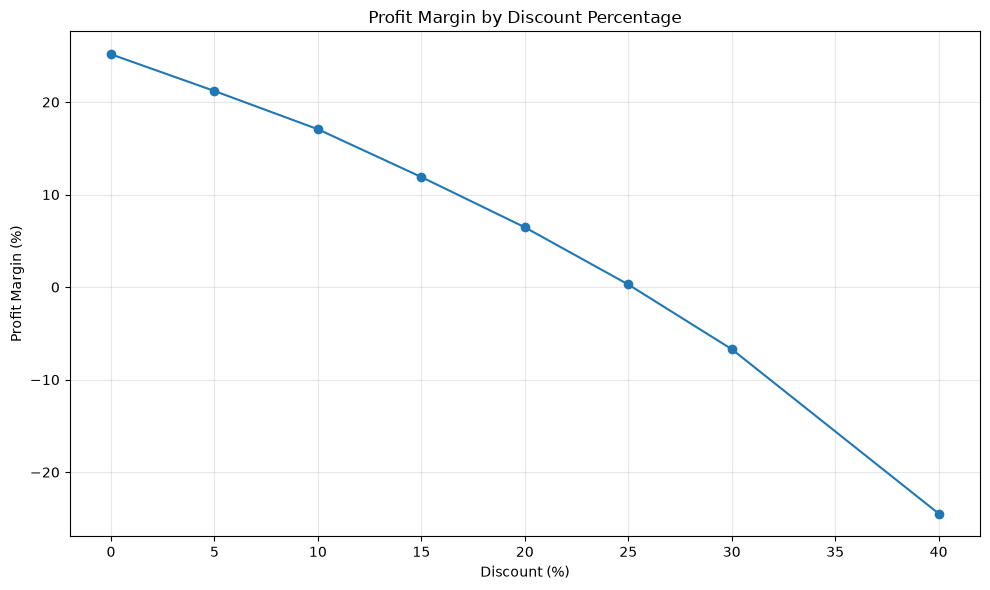

In [11]:
plt.figure(figsize=(10, 6))

plt.plot(
    discount_analysis["discount_pct"],
    discount_analysis["profit_margin_pct"],
    marker="o"
)

plt.title("Profit Margin by Discount Percentage")
plt.xlabel("Discount (%)")
plt.ylabel("Profit Margin (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

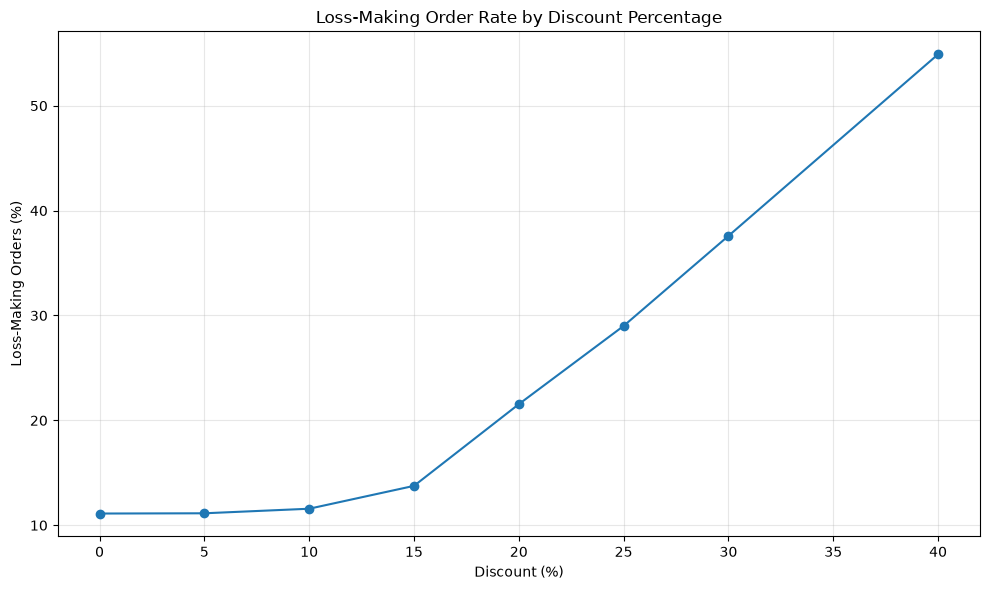

In [12]:
plt.figure(figsize=(10, 6))

plt.plot(
    discount_loss_analysis["discount_pct"],
    discount_loss_analysis["loss_making_rate_pct"],
    marker="o"
)

plt.title("Loss-Making Order Rate by Discount Percentage")
plt.xlabel("Discount (%)")
plt.ylabel("Loss-Making Orders (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 5.4 Delivery Delay & Return Analysis

This section analyzes whether longer delivery times are associated with higher product return rates and financial losses.

The objective is to understand the relationship between delivery performance, customer returns, and revenue leakage.

In [13]:
delivery_analysis = (
    df.groupby("delivery_days")
      .agg(
          total_orders=("order_id", "count"),
          returned_orders=("returned", "sum"),
          return_loss=("return_loss", "sum"),
          revenue_leakage=("revenue_leakage", "sum"),
          net_profit=("net_profit", "sum")
      )
      .reset_index()
)

delivery_analysis["return_rate_pct"] = (
    delivery_analysis["returned_orders"]
    / delivery_analysis["total_orders"]
    * 100
)

delivery_analysis.round(2)

,delivery_days,total_orders,returned_orders,return_loss,revenue_leakage,net_profit,return_rate_pct
0,1,5731,395,"6,728,958.31","25,756,256.29","10,211,176.69",6.89
1,2,10918,813,"13,397,795.40","48,257,196.12","18,839,896.77",7.45
2,3,19423,1468,"21,965,550.13","85,703,143.55","34,774,044.29",7.56
3,4,23822,1722,"29,775,491.54","107,286,496.76","43,379,455.17",7.23
4,5,20274,1485,"22,222,519.15","88,471,431.87","36,235,980.20",7.32
5,6,12543,1466,"23,567,422.67","65,081,752.44","20,430,158.71",11.69
6,7,5350,579,"9,785,462.66","26,663,328.74","8,738,285.66",10.82
7,8,1525,153,"1,660,218.05","6,038,597.64","2,662,529.09",10.03
8,9,353,45,"375,002.73","1,354,180.19","565,071.75",12.75
9,10,61,7,"225,976.50","408,318.24","97,706.48",11.48


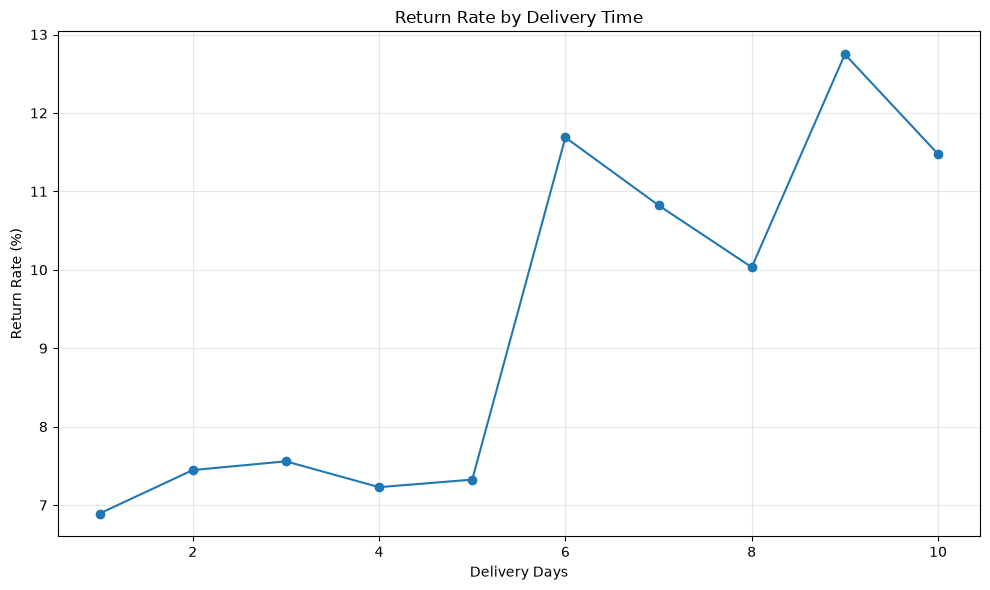

In [14]:
plt.figure(figsize=(10, 6))

plt.plot(
    delivery_analysis["delivery_days"],
    delivery_analysis["return_rate_pct"],
    marker="o"
)

plt.title("Return Rate by Delivery Time")
plt.xlabel("Delivery Days")
plt.ylabel("Return Rate (%)")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [15]:
return_delivery_comparison = (
    df.groupby("order_status")
      .agg(
          orders=("order_id", "count"),
          avg_delivery_days=("delivery_days", "mean"),
          avg_shipping_cost=("shipping_cost", "mean"),
          avg_revenue_leakage=("revenue_leakage", "mean"),
          avg_net_profit=("net_profit", "mean")
      )
      .reset_index()
)

return_delivery_comparison.round(2)

,order_status,orders,avg_delivery_days,avg_shipping_cost,avg_revenue_leakage,avg_net_profit
0,Cancelled,3223,4.20,210.94,"3,650.01",-408.45
1,Completed,88644,4.09,210.20,"3,236.71","2,018.92"
2,Returned,8133,4.34,210.79,"19,223.12",-210.79


In [16]:
df["delivery_group"] = np.where(
    df["delivery_days"] > 5,
    "Late Delivery (>5 Days)",
    "Standard Delivery (1-5 Days)"
)

late_delivery_analysis = (
    df.groupby("delivery_group")
      .agg(
          total_orders=("order_id", "count"),
          returned_orders=("returned", "sum"),
          return_loss=("return_loss", "sum")
      )
      .reset_index()
)

late_delivery_analysis["return_rate_pct"] = (
    late_delivery_analysis["returned_orders"]
    / late_delivery_analysis["total_orders"]
    * 100
)

late_delivery_analysis.round(2)

,delivery_group,total_orders,returned_orders,return_loss,return_rate_pct
0,Late Delivery (>5 Days),19832,2250,"35,614,082.61",11.35
1,Standard Delivery (1-5 Days),80168,5883,"94,090,314.53",7.34


## 5.5 Shipping Cost & Regional Profitability

This section analyzes regional differences in shipping costs, revenue, profitability, and revenue leakage.

The objective is to identify regions where logistics costs may be putting greater pressure on business profitability.

In [17]:
regional_analysis = (
    df.groupby("region")
      .agg(
          total_orders=("order_id", "count"),
          net_revenue=("net_revenue", "sum"),
          net_profit=("net_profit", "sum"),
          shipping_cost=("shipping_cost", "sum"),
          revenue_leakage=("revenue_leakage", "sum")
      )
      .reset_index()
)

regional_analysis["profit_margin_pct"] = np.where(
    regional_analysis["net_revenue"] != 0,
    regional_analysis["net_profit"]
    / regional_analysis["net_revenue"] * 100,
    0
)

regional_analysis["avg_shipping_cost"] = (
    regional_analysis["shipping_cost"]
    / regional_analysis["total_orders"]
)

regional_analysis = regional_analysis.sort_values(
    "net_profit",
    ascending=False
)

regional_analysis.round(2)

,region,total_orders,net_revenue,net_profit,shipping_cost,revenue_leakage,profit_margin_pct,avg_shipping_cost
3,West,30049,"441,047,934.82","52,379,850.39","5,762,075.68","133,324,413.21",11.88,191.76
2,South,28026,"423,669,472.83","49,793,054.69","5,670,870.37","124,885,804.71",11.75,202.34
1,North,23940,"365,344,622.64","42,070,516.78","5,163,526.57","113,193,565.21",11.52,215.69
0,East,17985,"263,507,018.87","31,690,882.95","4,430,538.10","83,616,918.71",12.03,246.35


In [18]:
regional_analysis["shipping_cost_pct_revenue"] = np.where(
    regional_analysis["net_revenue"] != 0,
    regional_analysis["shipping_cost"]
    / regional_analysis["net_revenue"] * 100,
    0
)

regional_analysis[
    [
        "region",
        "total_orders",
        "net_revenue",
        "net_profit",
        "profit_margin_pct",
        "shipping_cost",
        "avg_shipping_cost",
        "shipping_cost_pct_revenue",
        "revenue_leakage"
    ]
].round(2)

,region,total_orders,net_revenue,net_profit,profit_margin_pct,shipping_cost,avg_shipping_cost,shipping_cost_pct_revenue,revenue_leakage
3,West,30049,"441,047,934.82","52,379,850.39",11.88,"5,762,075.68",191.76,1.31,"133,324,413.21"
2,South,28026,"423,669,472.83","49,793,054.69",11.75,"5,670,870.37",202.34,1.34,"124,885,804.71"
1,North,23940,"365,344,622.64","42,070,516.78",11.52,"5,163,526.57",215.69,1.41,"113,193,565.21"
0,East,17985,"263,507,018.87","31,690,882.95",12.03,"4,430,538.10",246.35,1.68,"83,616,918.71"


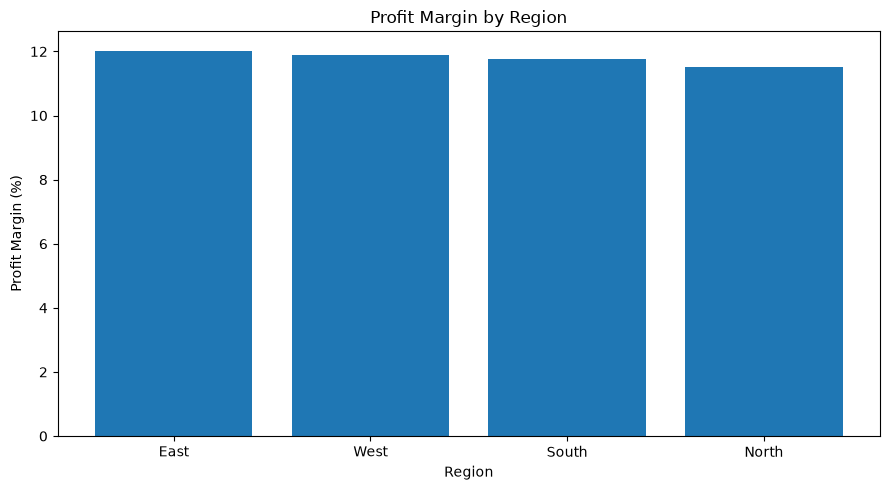

In [19]:
plot_data = regional_analysis.sort_values(
    "profit_margin_pct",
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data["region"],
    plot_data["profit_margin_pct"]
)

plt.title("Profit Margin by Region")
plt.xlabel("Region")
plt.ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

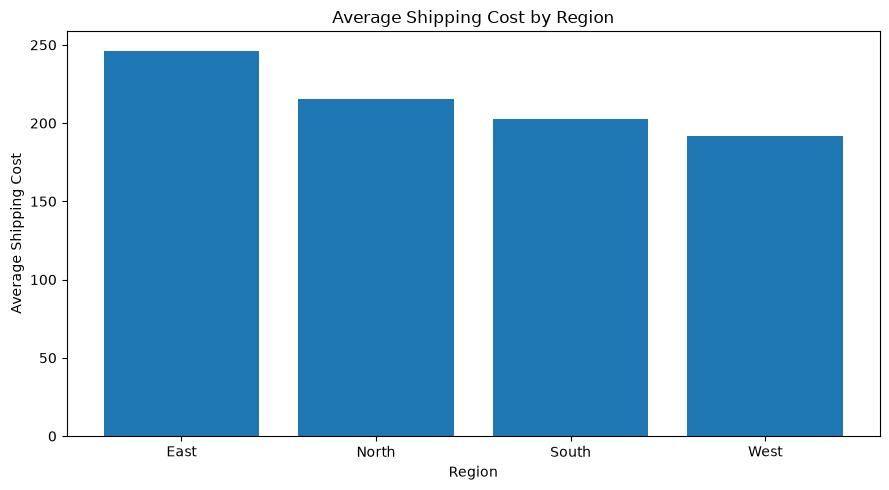

In [20]:
plot_data = regional_analysis.sort_values(
    "avg_shipping_cost",
    ascending=False
)

plt.figure(figsize=(9, 5))

plt.bar(
    plot_data["region"],
    plot_data["avg_shipping_cost"]
)

plt.title("Average Shipping Cost by Region")
plt.xlabel("Region")
plt.ylabel("Average Shipping Cost")

plt.tight_layout()
plt.show()

## 5.6 Category & Sub-Category Profitability Analysis

This section evaluates profitability across product categories and sub-categories.

The objective is to identify:
- High-revenue categories
- High-profit categories
- Low-margin categories
- Loss-making areas
- Categories contributing heavily to revenue leakage

In [21]:
category_analysis = (
    df.groupby("category")
      .agg(
          total_orders=("order_id", "count"),
          gross_revenue=("gross_revenue", "sum"),
          net_revenue=("net_revenue", "sum"),
          net_profit=("net_profit", "sum"),
          revenue_leakage=("revenue_leakage", "sum")
      )
      .reset_index()
)

category_analysis["profit_margin_pct"] = np.where(
    category_analysis["net_revenue"] != 0,
    category_analysis["net_profit"]
    / category_analysis["net_revenue"] * 100,
    0
)

category_analysis = category_analysis.sort_values(
    "net_profit",
    ascending=False
)

category_analysis.round(2)

,category,total_orders,gross_revenue,net_revenue,net_profit,revenue_leakage,profit_margin_pct
3,Home & Furniture,27260,"371,940,358.65","285,259,995.45","65,499,079.49","82,443,990.12",22.96
1,Electronics,27925,"1,402,678,722.53","1,058,227,889.39","55,000,402.45","314,427,896.07",5.20
2,Fashion,29901,"155,017,255.29","112,623,889.82","41,220,887.79","44,683,782.04",36.60
0,Beauty,14914,"49,150,315.73","37,457,274.50","14,213,935.08","13,465,033.61",37.95


In [22]:
category_loss_analysis = (
    df.groupby("category")
      .agg(
          total_orders=("order_id", "count"),
          loss_making_orders=("is_loss_making", "sum")
      )
      .reset_index()
)

category_loss_analysis["loss_making_rate_pct"] = (
    category_loss_analysis["loss_making_orders"]
    / category_loss_analysis["total_orders"] * 100
)

category_loss_analysis = category_loss_analysis.sort_values(
    "loss_making_rate_pct",
    ascending=False
)

category_loss_analysis.round(2)

,category,total_orders,loss_making_orders,loss_making_rate_pct
1,Electronics,27925,9193,32.92
2,Fashion,29901,4598,15.38
3,Home & Furniture,27260,3888,14.26
0,Beauty,14914,2082,13.96


In [23]:
subcategory_analysis = (
    df.groupby(["category", "sub_category"])
      .agg(
          total_orders=("order_id", "count"),
          net_revenue=("net_revenue", "sum"),
          net_profit=("net_profit", "sum"),
          revenue_leakage=("revenue_leakage", "sum")
      )
      .reset_index()
)

subcategory_analysis["profit_margin_pct"] = np.where(
    subcategory_analysis["net_revenue"] != 0,
    subcategory_analysis["net_profit"]
    / subcategory_analysis["net_revenue"] * 100,
    0
)

subcategory_analysis = subcategory_analysis.sort_values(
    "profit_margin_pct"
)

subcategory_analysis.round(2)

,category,sub_category,total_orders,net_revenue,net_profit,revenue_leakage,profit_margin_pct
4,Electronics,Laptops,9202,"684,385,642.13","20,574,130.85","201,770,137.43",3.01
5,Electronics,Smartphones,9272,"341,318,557.94","25,019,578.74","101,266,735.88",7.33
9,Home & Furniture,Furniture,9138,"198,039,082.43","37,317,924.71","54,829,124.15",18.84
3,Electronics,Accessories,9451,"32,523,689.32","9,406,692.86","11,391,022.76",28.92
11,Home & Furniture,Kitchen,9132,"50,233,933.71","15,034,157.69","15,433,997.01",29.93
6,Fashion,Footwear,9968,"44,219,265.21","14,944,083.82","17,364,188.89",33.80
10,Home & Furniture,Home Decor,8990,"36,986,979.31","13,146,997.09","12,180,868.96",35.54
1,Beauty,Hair Care,4994,"8,829,466.86","3,184,520.65","3,464,801.37",36.07
7,Fashion,Men Clothing,9981,"30,562,113.01","11,113,661.59","12,428,127.93",36.36
0,Beauty,Fragrances,4931,"17,831,001.20","6,638,426.93","5,988,256.09",37.23


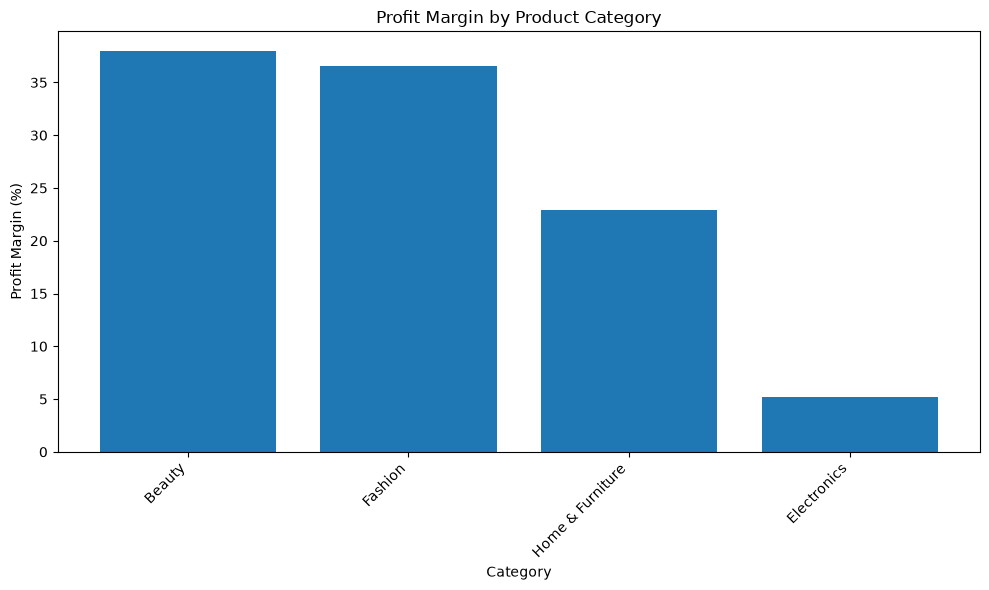

In [24]:
plot_data = category_analysis.sort_values(
    "profit_margin_pct",
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.bar(
    plot_data["category"],
    plot_data["profit_margin_pct"]
)

plt.title("Profit Margin by Product Category")
plt.xlabel("Category")
plt.ylabel("Profit Margin (%)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [25]:
lowest_margin_subcategories = (
    subcategory_analysis
    .sort_values("profit_margin_pct")
    .head(10)
)

lowest_margin_subcategories.round(2)

,category,sub_category,total_orders,net_revenue,net_profit,revenue_leakage,profit_margin_pct
4,Electronics,Laptops,9202,"684,385,642.13","20,574,130.85","201,770,137.43",3.01
5,Electronics,Smartphones,9272,"341,318,557.94","25,019,578.74","101,266,735.88",7.33
9,Home & Furniture,Furniture,9138,"198,039,082.43","37,317,924.71","54,829,124.15",18.84
3,Electronics,Accessories,9451,"32,523,689.32","9,406,692.86","11,391,022.76",28.92
11,Home & Furniture,Kitchen,9132,"50,233,933.71","15,034,157.69","15,433,997.01",29.93
6,Fashion,Footwear,9968,"44,219,265.21","14,944,083.82","17,364,188.89",33.80
10,Home & Furniture,Home Decor,8990,"36,986,979.31","13,146,997.09","12,180,868.96",35.54
1,Beauty,Hair Care,4994,"8,829,466.86","3,184,520.65","3,464,801.37",36.07
7,Fashion,Men Clothing,9981,"30,562,113.01","11,113,661.59","12,428,127.93",36.36
0,Beauty,Fragrances,4931,"17,831,001.20","6,638,426.93","5,988,256.09",37.23


## 5.7 Product-Level Profitability Analysis

This section analyzes individual product performance to identify products that generate significant revenue but deliver weak or negative profitability.

The objective is to identify:
- Highest-revenue products
- Highest-profit products
- Loss-making products
- High-revenue but low-margin products
- Products contributing significantly to revenue leakage

In [26]:
product_analysis = (
    df.groupby(
        ["product_id", "product_name", "category", "sub_category"]
    )
    .agg(
        total_orders=("order_id", "count"),
        gross_revenue=("gross_revenue", "sum"),
        net_revenue=("net_revenue", "sum"),
        net_profit=("net_profit", "sum"),
        revenue_leakage=("revenue_leakage", "sum")
    )
    .reset_index()
)

product_analysis["profit_margin_pct"] = np.where(
    product_analysis["net_revenue"] != 0,
    product_analysis["net_profit"]
    / product_analysis["net_revenue"] * 100,
    0
)

print("Products Analyzed:", len(product_analysis))

product_analysis.head()

Products Analyzed: 99441


,product_id,product_name,category,sub_category,total_orders,gross_revenue,net_revenue,net_profit,revenue_leakage,profit_margin_pct
0,PRD0001,Accessories Item 089,Electronics,Accessories,1,"15,686.78","13,333.76","4,269.55","2,669.11",32.02
1,PRD0001,Footwear Item 035,Fashion,Footwear,1,"10,835.79","10,835.79","4,828.82",325.45,44.56
2,PRD0001,Footwear Item 045,Fashion,Footwear,1,"6,459.51","5,167.61","1,631.88","1,629.00",31.58
3,PRD0001,Footwear Item 071,Fashion,Footwear,1,"15,766.53","14,978.20","6,173.50","1,141.43",41.22
4,PRD0001,Footwear Item 153,Fashion,Footwear,1,"4,294.01","3,435.21",962.72,"1,074.03",28.03


In [27]:
top_revenue_products = (
    product_analysis
    .sort_values("net_revenue", ascending=False)
    .head(10)
)

top_revenue_products[
    [
        "product_id",
        "product_name",
        "category",
        "net_revenue",
        "net_profit",
        "profit_margin_pct",
        "revenue_leakage"
    ]
].round(2)

,product_id,product_name,category,net_revenue,net_profit,profit_margin_pct,revenue_leakage
44855,PRD1128,Laptops Item 225,Electronics,"574,319.46","82,349.96",14.34,528.40
61550,PRD1551,Laptops Item 070,Electronics,"457,068.97","46,991.56",10.28,"40,361.07"
88292,PRD2223,Laptops Item 123,Electronics,"422,813.44","69,041.79",16.33,427.70
4915,PRD0125,Laptops Item 123,Electronics,"418,414.40","81,308.70",19.43,531.20
27659,PRD0696,Laptops Item 189,Electronics,"414,062.70","82,115.90",19.83,300.25
2946,PRD0076,Laptops Item 221,Electronics,"406,984.12","-34,861.53",-8.57,"108,301.59"
44580,PRD1121,Laptops Item 078,Electronics,"399,395.58","58,169.26",14.56,"21,307.14"
23244,PRD0586,Laptops Item 210,Electronics,"393,171.59","88,567.99",22.53,309.15
14686,PRD0372,Laptops Item 099,Electronics,"393,022.01","53,850.15",13.70,"21,003.58"
35536,PRD0895,Laptops Item 190,Electronics,"391,238.71","58,789.83",15.03,"20,864.79"


In [28]:
top_profit_products = (
    product_analysis
    .sort_values("net_profit", ascending=False)
    .head(10)
)

top_profit_products[
    [
        "product_id",
        "product_name",
        "category",
        "net_revenue",
        "net_profit",
        "profit_margin_pct"
    ]
].round(2)

,product_id,product_name,category,net_revenue,net_profit,profit_margin_pct
23244,PRD0586,Laptops Item 210,Electronics,"393,171.59","88,567.99",22.53
44855,PRD1128,Laptops Item 225,Electronics,"574,319.46","82,349.96",14.34
27659,PRD0696,Laptops Item 189,Electronics,"414,062.70","82,115.90",19.83
4915,PRD0125,Laptops Item 123,Electronics,"418,414.40","81,308.70",19.43
52369,PRD1319,Laptops Item 153,Electronics,"338,730.01","73,660.61",21.75
55718,PRD1402,Laptops Item 191,Electronics,"356,545.19","72,214.84",20.25
83284,PRD2097,Laptops Item 197,Electronics,"340,370.16","71,934.84",21.13
33802,PRD0850,Laptops Item 046,Electronics,"329,707.12","71,375.37",21.65
66674,PRD1679,Laptops Item 209,Electronics,"331,485.74","70,783.43",21.35
88292,PRD2223,Laptops Item 123,Electronics,"422,813.44","69,041.79",16.33


In [29]:
loss_making_products = product_analysis[
    product_analysis["net_profit"] < 0
].copy()

loss_making_products = loss_making_products.sort_values(
    "net_profit"
)

print("Total Loss-Making Products:", len(loss_making_products))

loss_making_products[
    [
        "product_id",
        "product_name",
        "category",
        "total_orders",
        "net_revenue",
        "net_profit",
        "profit_margin_pct",
        "revenue_leakage"
    ]
].head(10).round(2)

Total Loss-Making Products: 19580


,product_id,product_name,category,total_orders,net_revenue,net_profit,profit_margin_pct,revenue_leakage
24807,PRD0624,Laptops Item 043,Electronics,1,"229,366.67","-103,027.53",-44.92,"153,301.01"
96026,PRD2417,Laptops Item 080,Electronics,1,"247,203.50","-94,435.05",-38.20,"165,070.83"
41193,PRD1037,Laptops Item 065,Electronics,1,"200,965.45","-82,306.21",-40.96,"134,352.02"
4248,PRD0110,Laptops Item 123,Electronics,1,"195,419.03","-75,421.19",-38.59,"130,446.10"
49875,PRD1256,Laptops Item 138,Electronics,1,"196,709.15","-72,896.79",-37.06,"131,340.98"
83936,PRD2113,Laptops Item 017,Electronics,1,"158,794.44","-68,910.07",-43.40,"106,160.07"
68455,PRD1724,Laptops Item 183,Electronics,1,"161,967.53","-67,922.22",-41.94,"108,354.47"
76064,PRD1914,Laptops Item 284,Electronics,1,"154,000.52","-64,721.65",-42.03,"102,876.83"
83589,PRD2104,Laptops Item 288,Electronics,1,"265,537.17","-63,531.48",-23.93,"114,102.89"
52078,PRD1311,Laptops Item 126,Electronics,1,"184,331.68","-62,983.46",-34.17,"123,191.32"


In [30]:
median_product_revenue = product_analysis["net_revenue"].median()

high_revenue_low_margin = product_analysis[
    (product_analysis["net_revenue"] > median_product_revenue) &
    (product_analysis["profit_margin_pct"] < 10)
].copy()

high_revenue_low_margin = high_revenue_low_margin.sort_values(
    "net_revenue",
    ascending=False
)

print(
    "Median Product Revenue:",
    round(median_product_revenue, 2)
)

print(
    "High-Revenue Low-Margin Products:",
    len(high_revenue_low_margin)
)

high_revenue_low_margin[
    [
        "product_id",
        "product_name",
        "category",
        "net_revenue",
        "net_profit",
        "profit_margin_pct",
        "revenue_leakage"
    ]
].head(10).round(2)

Median Product Revenue: 3804.86
High-Revenue Low-Margin Products: 12408


,product_id,product_name,category,net_revenue,net_profit,profit_margin_pct,revenue_leakage
2946,PRD0076,Laptops Item 221,Electronics,"406,984.12","-34,861.53",-8.57,"108,301.59"
4777,PRD0122,Laptops Item 221,Electronics,"371,481.35","16,988.38",4.57,"41,670.17"
91448,PRD2302,Laptops Item 282,Electronics,"360,139.03","26,702.62",7.41,"40,271.21"
95281,PRD2398,Laptops Item 053,Electronics,"357,229.59","35,600.65",9.97,"40,092.87"
54930,PRD1383,Laptops Item 247,Electronics,"354,352.24","20,169.51",5.69,"39,648.25"
87170,PRD2194,Laptops Item 059,Electronics,"353,108.28","12,129.58",3.44,"39,545.10"
59009,PRD1486,Laptops Item 143,Electronics,"351,765.68","21,190.56",6.02,"39,260.99"
13026,PRD0329,Laptops Item 140,Electronics,"348,604.53","25,621.37",7.35,"61,992.46"
32263,PRD0812,Laptops Item 066,Electronics,"347,108.47","19,138.78",5.51,"61,482.43"
78392,PRD1974,Laptops Item 173,Electronics,"332,865.68","30,660.17",9.21,"37,232.44"


In [31]:
highest_leakage_products = (
    product_analysis
    .sort_values("revenue_leakage", ascending=False)
    .head(10)
)

highest_leakage_products[
    [
        "product_id",
        "product_name",
        "category",
        "net_revenue",
        "net_profit",
        "profit_margin_pct",
        "revenue_leakage"
    ]
].round(2)

,product_id,product_name,category,net_revenue,net_profit,profit_margin_pct,revenue_leakage
96848,PRD2437,Laptops Item 093,Electronics,0.00,-313.81,0.00,"413,233.12"
61128,PRD1540,Laptops Item 046,Electronics,0.00,-247.97,0.00,"399,855.54"
62187,PRD1567,Laptops Item 078,Electronics,0.00,-307.72,0.00,"381,440.18"
19672,PRD0498,Laptops Item 013,Electronics,0.00,-390.95,0.00,"379,876.55"
54701,PRD1378,Laptops Item 001,Electronics,0.00,-269.54,0.00,"378,872.28"
78243,PRD1970,Laptops Item 226,Electronics,0.00,-402.65,0.00,"375,793.35"
29613,PRD0746,Laptops Item 095,Electronics,0.00,-530.52,0.00,"371,182.00"
82018,PRD2066,Laptops Item 193,Electronics,0.00,-380.08,0.00,"345,778.66"
17671,PRD0447,Laptops Item 115,Electronics,0.00,-422.92,0.00,"335,407.30"
83629,PRD2105,Laptops Item 294,Electronics,0.00,-360.11,0.00,"332,278.40"


## 5.8 Customer Segment Performance

This section analyzes customer segment performance across revenue, profitability, returns, cancellations, and revenue leakage.

The objective is to identify which customer segments create the most business value and which segments show higher profitability or leakage risk.

In [32]:
segment_analysis = (
    df.groupby("customer_segment")
      .agg(
          total_orders=("order_id", "count"),
          unique_customers=("customer_id", "nunique"),
          gross_revenue=("gross_revenue", "sum"),
          net_revenue=("net_revenue", "sum"),
          net_profit=("net_profit", "sum"),
          revenue_leakage=("revenue_leakage", "sum"),
          returned_orders=("returned", "sum")
      )
      .reset_index()
)

segment_analysis["profit_margin_pct"] = np.where(
    segment_analysis["net_revenue"] != 0,
    segment_analysis["net_profit"]
    / segment_analysis["net_revenue"] * 100,
    0
)

segment_analysis["return_rate_pct"] = (
    segment_analysis["returned_orders"]
    / segment_analysis["total_orders"] * 100
)

segment_analysis.round(2)

,customer_segment,total_orders,unique_customers,gross_revenue,net_revenue,net_profit,revenue_leakage,returned_orders,profit_margin_pct,return_rate_pct
0,Consumer,65934,19239,"1,309,231,307.91","993,409,726.18","116,285,308.94","296,986,313.54",5276,11.71,8.00
1,Corporate,19913,12554,"390,068,134.12","291,296,910.15","35,375,414.58","91,631,274.53",1632,12.14,8.20
2,Home Office,14153,10056,"279,487,210.17","208,862,412.83","24,273,581.29","66,403,113.77",1225,11.62,8.66


In [33]:
cancelled_by_segment = (
    df.assign(
        is_cancelled=(df["order_status"] == "Cancelled").astype(int)
    )
    .groupby("customer_segment")["is_cancelled"]
    .sum()
)

segment_analysis["cancelled_orders"] = (
    segment_analysis["customer_segment"]
    .map(cancelled_by_segment)
)

segment_analysis["cancellation_rate_pct"] = (
    segment_analysis["cancelled_orders"]
    / segment_analysis["total_orders"] * 100
)

segment_analysis.round(2)

,customer_segment,total_orders,unique_customers,gross_revenue,net_revenue,net_profit,revenue_leakage,returned_orders,profit_margin_pct,return_rate_pct,cancelled_orders,cancellation_rate_pct
0,Consumer,65934,19239,"1,309,231,307.91","993,409,726.18","116,285,308.94","296,986,313.54",5276,11.71,8.00,2086,3.16
1,Corporate,19913,12554,"390,068,134.12","291,296,910.15","35,375,414.58","91,631,274.53",1632,12.14,8.20,665,3.34
2,Home Office,14153,10056,"279,487,210.17","208,862,412.83","24,273,581.29","66,403,113.77",1225,11.62,8.66,472,3.33


In [34]:
segment_analysis["avg_order_value"] = (
    segment_analysis["net_revenue"]
    / segment_analysis["total_orders"]
)

segment_analysis[
    [
        "customer_segment",
        "total_orders",
        "unique_customers",
        "net_revenue",
        "net_profit",
        "profit_margin_pct",
        "avg_order_value",
        "return_rate_pct",
        "cancellation_rate_pct",
        "revenue_leakage"
    ]
].round(2)

,customer_segment,total_orders,unique_customers,net_revenue,net_profit,profit_margin_pct,avg_order_value,return_rate_pct,cancellation_rate_pct,revenue_leakage
0,Consumer,65934,19239,"993,409,726.18","116,285,308.94",11.71,"15,066.73",8.00,3.16,"296,986,313.54"
1,Corporate,19913,12554,"291,296,910.15","35,375,414.58",12.14,"14,628.48",8.20,3.34,"91,631,274.53"
2,Home Office,14153,10056,"208,862,412.83","24,273,581.29",11.62,"14,757.47",8.66,3.33,"66,403,113.77"


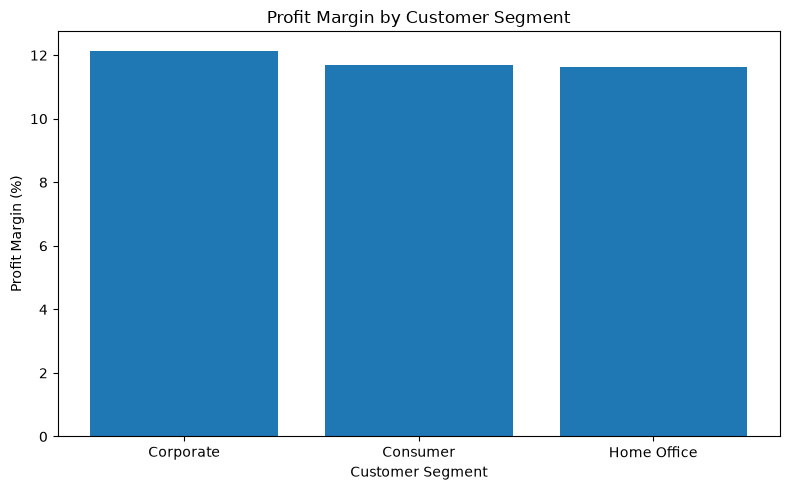

In [35]:
plot_data = segment_analysis.sort_values(
    "profit_margin_pct",
    ascending=False
)

plt.figure(figsize=(8, 5))

plt.bar(
    plot_data["customer_segment"],
    plot_data["profit_margin_pct"]
)

plt.title("Profit Margin by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()

In [36]:
segment_analysis["leakage_per_order"] = (
    segment_analysis["revenue_leakage"]
    / segment_analysis["total_orders"]
)

segment_analysis[
    [
        "customer_segment",
        "total_orders",
        "profit_margin_pct",
        "return_rate_pct",
        "cancellation_rate_pct",
        "leakage_per_order"
    ]
].sort_values(
    "leakage_per_order",
    ascending=False
).round(2)

,customer_segment,total_orders,profit_margin_pct,return_rate_pct,cancellation_rate_pct,leakage_per_order
2,Home Office,14153,11.62,8.66,3.33,"4,691.80"
1,Corporate,19913,12.14,8.20,3.34,"4,601.58"
0,Consumer,65934,11.71,8.00,3.16,"4,504.30"


## 5.9 Monthly Revenue, Profit & Leakage Trends

This section analyzes monthly business performance across the two-year dataset.

The objective is to identify:
- Revenue trends
- Profit trends
- Revenue leakage trends
- Monthly profitability changes
- High- and low-performing periods

In [37]:
df["order_date"] = pd.to_datetime(df["order_date"])
print("Date Type:", df["order_date"].dtype)

Date Type: datetime64[us]


In [38]:
df["year_month"] = df["order_date"].dt.to_period("M")

In [39]:
monthly_analysis = (
    df.groupby("year_month")
      .agg(
          total_orders=("order_id", "count"),
          gross_revenue=("gross_revenue", "sum"),
          net_revenue=("net_revenue", "sum"),
          net_profit=("net_profit", "sum"),
          revenue_leakage=("revenue_leakage", "sum")
      )
      .reset_index()
)

monthly_analysis["profit_margin_pct"] = np.where(
    monthly_analysis["net_revenue"] != 0,
    monthly_analysis["net_profit"]
    / monthly_analysis["net_revenue"] * 100,
    0
)

monthly_analysis.round(2)

C:\Users\iamga\AppData\Local\Temp\ipykernel_25188\117014902.py:20: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  monthly_analysis.round(2)


,year_month,total_orders,gross_revenue,net_revenue,net_profit,revenue_leakage,profit_margin_pct
0,2024-01,4283,"86,902,909.18","66,121,375.06","7,288,461.66","19,286,739.04",11.02
1,2024-02,3933,"76,263,866.31","56,074,446.65","6,297,734.31","18,813,142.05",11.23
2,2024-03,4262,"85,444,886.93","64,677,972.02","7,160,450.81","19,152,016.98",11.07
3,2024-04,4097,"82,019,566.00","62,239,465.80","7,371,743.01","19,109,580.49",11.84
4,2024-05,4207,"84,690,190.51","63,792,606.46","7,317,665.19","20,187,696.17",11.47
5,2024-06,4126,"82,006,783.01","62,127,565.24","7,755,081.45","18,713,903.35",12.48
6,2024-07,4225,"82,275,737.71","61,580,554.09","7,506,387.95","19,160,340.80",12.19
7,2024-08,4297,"84,358,769.05","62,865,655.55","7,373,144.53","19,949,669.27",11.73
8,2024-09,4111,"82,649,329.74","62,524,644.37","6,836,289.45","18,878,429.17",10.93
9,2024-10,4236,"84,188,408.41","63,867,064.83","7,921,801.59","18,863,521.64",12.40


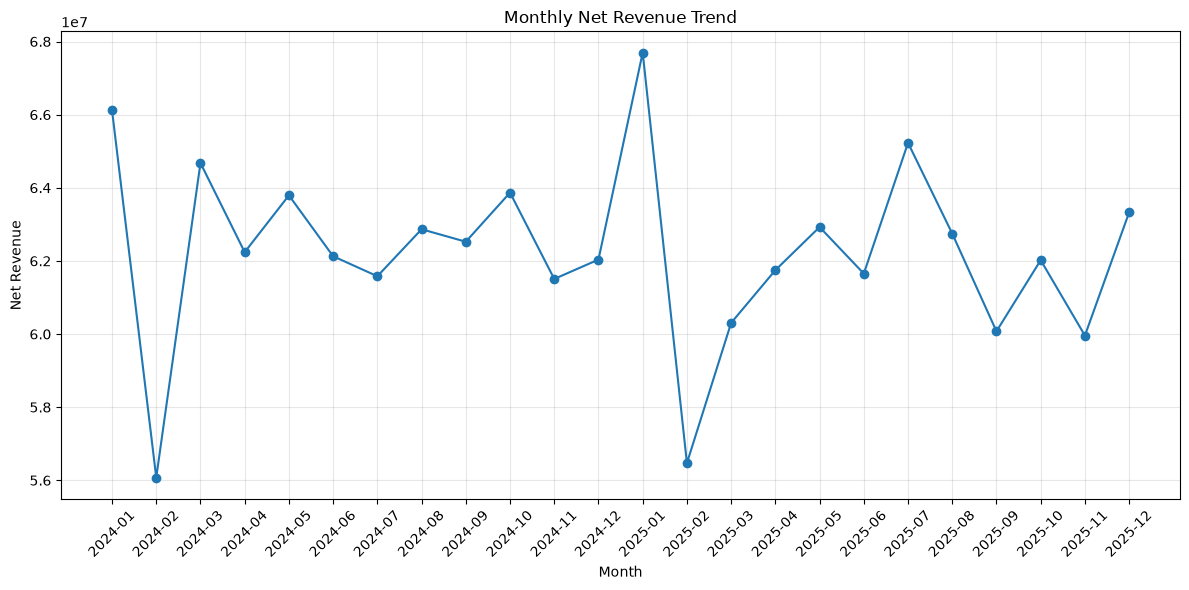

In [40]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_analysis["year_month"].astype(str),
    monthly_analysis["net_revenue"],
    marker="o"
)

plt.title("Monthly Net Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Net Revenue")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

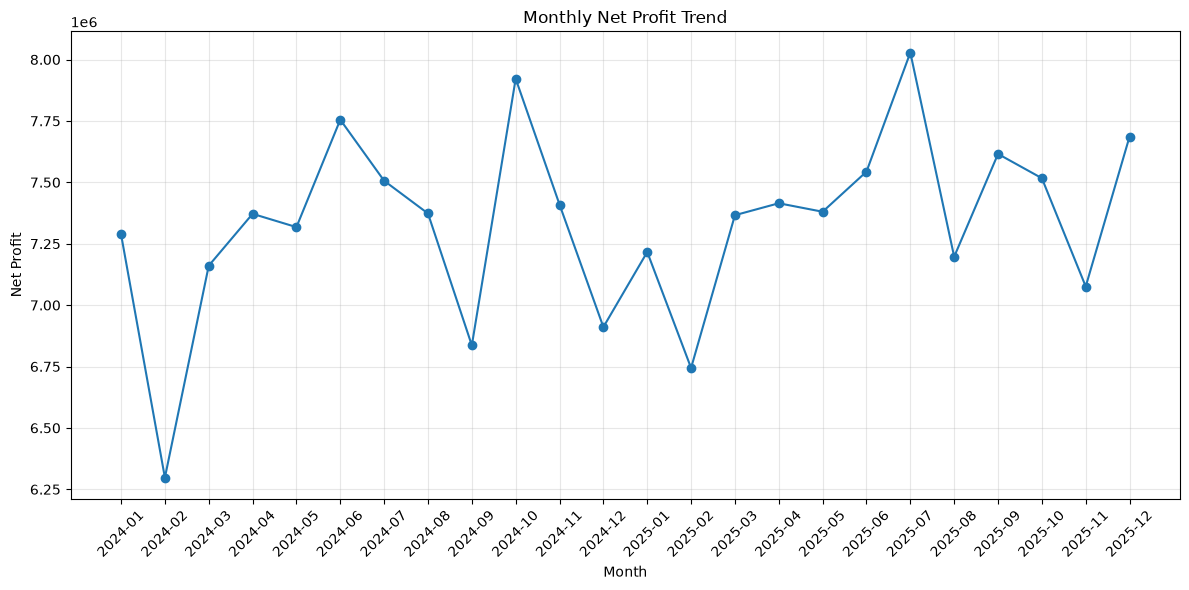

In [41]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_analysis["year_month"].astype(str),
    monthly_analysis["net_profit"],
    marker="o"
)

plt.title("Monthly Net Profit Trend")
plt.xlabel("Month")
plt.ylabel("Net Profit")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

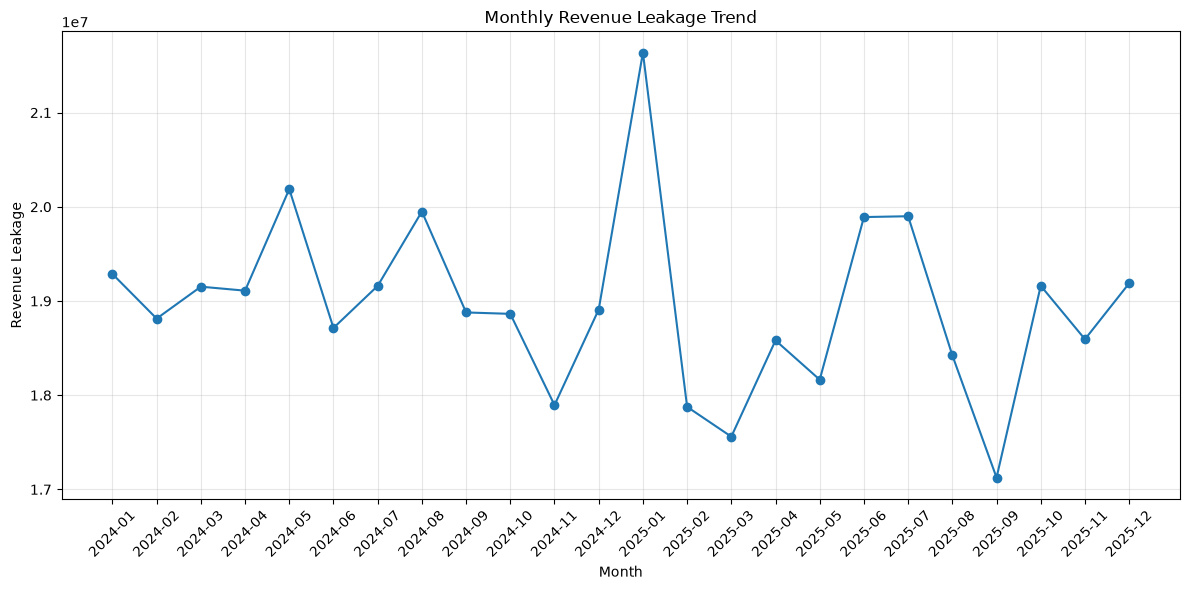

In [42]:
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_analysis["year_month"].astype(str),
    monthly_analysis["revenue_leakage"],
    marker="o"
)

plt.title("Monthly Revenue Leakage Trend")
plt.xlabel("Month")
plt.ylabel("Revenue Leakage")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [43]:
best_profit_month = monthly_analysis.loc[
    monthly_analysis["net_profit"].idxmax()
]

worst_profit_month = monthly_analysis.loc[
    monthly_analysis["net_profit"].idxmin()
]

print("Highest Profit Month:")
print(best_profit_month)

print("\nLowest Profit Month:")
print(worst_profit_month)

Highest Profit Month:
year_month                2025-07
total_orders                 4280
gross_revenue       86,858,576.53
net_revenue         65,228,093.17
net_profit           8,028,334.86
revenue_leakage     19,899,784.29
profit_margin_pct           12.31
Name: 18, dtype: object

Lowest Profit Month:
year_month                2024-02
total_orders                 3933
gross_revenue       76,263,866.31
net_revenue         56,074,446.65
net_profit           6,297,734.31
revenue_leakage     18,813,142.05
profit_margin_pct           11.23
Name: 1, dtype: object


## 5.10 Returns & Cancellations Deep Dive

This section analyzes the financial and operational impact of returned and cancelled orders.

The objective is to understand:
- Return and cancellation volumes
- Return and cancellation rates
- Financial losses associated with these orders
- Major reasons for product returns

In [44]:
status_analysis = (
    df.groupby("order_status")
      .agg(
          total_orders=("order_id", "count"),
          gross_revenue=("gross_revenue", "sum"),
          net_revenue=("net_revenue", "sum"),
          net_profit=("net_profit", "sum"),
          revenue_leakage=("revenue_leakage", "sum")
      )
      .reset_index()
)

status_analysis["order_pct"] = (
    status_analysis["total_orders"]
    / len(df) * 100
)

status_analysis.round(2)

,order_status,total_orders,gross_revenue,net_revenue,net_profit,revenue_leakage,order_pct
0,Cancelled,3223,"62,308,037.95",0.00,"-1,316,444.17","11,763,996.95",3.22
1,Completed,88644,"1,761,851,348.91","1,493,569,049.16","178,965,115.68","286,915,072.85",88.64
2,Returned,8133,"154,627,265.34",0.00,"-1,714,366.70","156,341,632.04",8.13


In [45]:
total_return_loss = df["return_loss"].sum()
total_cancellation_loss = df["cancellation_loss"].sum()

print(f"Total Return Loss: ₹{total_return_loss:,.2f}")
print(f"Total Cancellation Loss: ₹{total_cancellation_loss:,.2f}")

Total Return Loss: ₹129,704,397.14
Total Cancellation Loss: ₹636,573.25


In [46]:
return_reason_analysis = (
    df[df["order_status"] == "Returned"]
    .groupby("return_reason")
    .agg(
        returned_orders=("order_id", "count"),
        return_loss=("return_loss", "sum"),
        revenue_leakage=("revenue_leakage", "sum")
    )
    .reset_index()
)

return_reason_analysis["return_pct"] = (
    return_reason_analysis["returned_orders"]
    / return_reason_analysis["returned_orders"].sum()
    * 100
)

return_reason_analysis = return_reason_analysis.sort_values(
    "returned_orders",
    ascending=False
)

return_reason_analysis.round(2)

,return_reason,returned_orders,return_loss,revenue_leakage,return_pct
4,Size/Fit Issue,2169,"22,997,092.75","27,889,006.29",26.67
2,Late Delivery,2028,"35,575,061.93","42,526,565.09",24.94
0,Changed Mind,1007,"18,925,892.30","22,828,471.63",12.38
3,Quality Issue,1001,"17,506,183.34","21,131,479.00",12.31
5,Wrong Item,997,"17,596,195.46","21,433,643.21",12.26
1,Damaged Product,931,"17,103,971.36","20,532,466.82",11.45


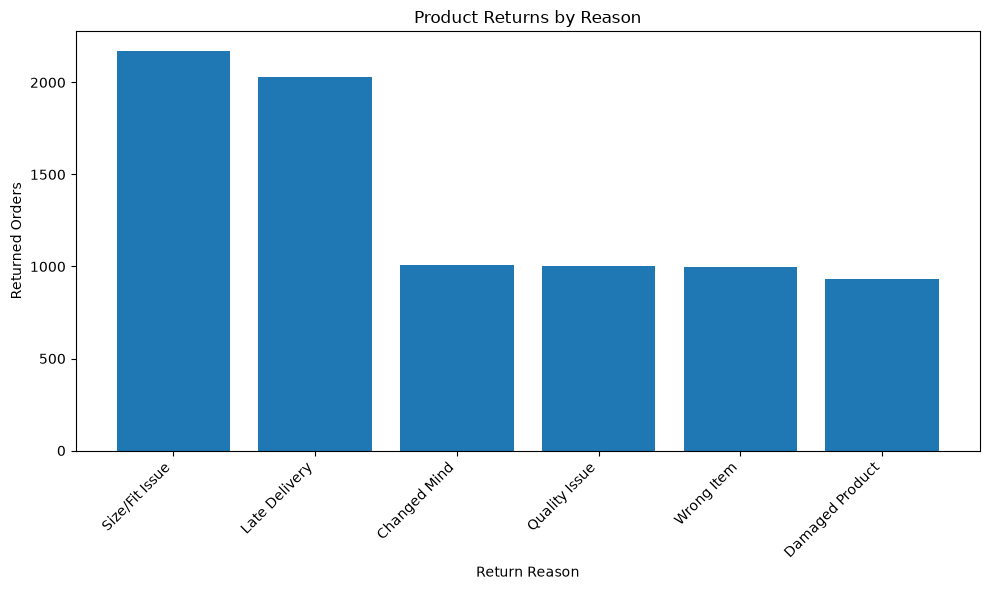

In [47]:
plt.figure(figsize=(10, 6))

plt.bar(
    return_reason_analysis["return_reason"],
    return_reason_analysis["returned_orders"]
)

plt.title("Product Returns by Reason")
plt.xlabel("Return Reason")
plt.ylabel("Returned Orders")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [48]:
returned_count = (df["order_status"] == "Returned").sum()
cancelled_count = (df["order_status"] == "Cancelled").sum()

avg_return_loss = total_return_loss / returned_count
avg_cancellation_loss = total_cancellation_loss / cancelled_count

print(f"Average Loss per Returned Order: ₹{avg_return_loss:,.2f}")
print(f"Average Loss per Cancelled Order: ₹{avg_cancellation_loss:,.2f}")

Average Loss per Returned Order: ₹15,947.92
Average Loss per Cancelled Order: ₹197.51


## 5.11 Completed Orders Profitability Deep Dive

Not all profitability problems come from returns or cancellations.

This section focuses specifically on completed orders to identify transactions that successfully generated revenue but still resulted in negative profit.

The objective is to investigate whether discounts, shipping costs, product margins, or other cost pressures are associated with these loss-making completed orders.

In [49]:
completed_orders = df[
    df["order_status"] == "Completed"
].copy()

print("Total Completed Orders:", len(completed_orders))

completed_loss_orders = completed_orders[
    completed_orders["net_profit"] < 0
].copy()

print(
    "Loss-Making Completed Orders:",
    len(completed_loss_orders)
)

print(
    "Loss-Making Completed Order Rate:",
    round(
        len(completed_loss_orders)
        / len(completed_orders) * 100,
        2
    ),
    "%"
)

Total Completed Orders: 88644
Loss-Making Completed Orders: 8405
Loss-Making Completed Order Rate: 9.48 %


In [50]:
completed_orders["profit_status"] = np.where(
    completed_orders["net_profit"] < 0,
    "Loss-Making",
    "Profitable"
)

completed_comparison = (
    completed_orders.groupby("profit_status")
    .agg(
        total_orders=("order_id", "count"),
        avg_gross_revenue=("gross_revenue", "mean"),
        avg_discount_pct=("discount_pct", "mean"),
        avg_discount_amount=("discount_amount", "mean"),
        avg_shipping_cost=("shipping_cost", "mean"),
        avg_cogs=("cogs", "mean"),
        avg_net_revenue=("net_revenue", "mean"),
        avg_net_profit=("net_profit", "mean"),
        avg_revenue_leakage=("revenue_leakage", "mean")
    )
    .reset_index()
)

completed_comparison.round(2)

,profit_status,total_orders,avg_gross_revenue,avg_discount_pct,avg_discount_amount,avg_shipping_cost,avg_cogs,avg_net_revenue,avg_net_profit,avg_revenue_leakage
0,Loss-Making,8405,"53,224.53",27.80,"14,147.53",214.58,"43,154.54","39,077.00","-4,292.13","14,362.11"
1,Profitable,80239,"16,382.30",14.02,"1,861.59",209.74,"11,630.97","14,520.71","2,680.00","2,071.33"


In [51]:
completed_loss_reasons = (
    completed_loss_orders
    .groupby("leakage_reason")
    .agg(
        total_orders=("order_id", "count"),
        total_loss=("net_profit", "sum"),
        revenue_leakage=("revenue_leakage", "sum")
    )
    .reset_index()
)

completed_loss_reasons["order_pct"] = (
    completed_loss_reasons["total_orders"]
    / len(completed_loss_orders) * 100
)

completed_loss_reasons = completed_loss_reasons.sort_values(
    "total_orders",
    ascending=False
)

completed_loss_reasons.round(2)

,leakage_reason,total_orders,total_loss,revenue_leakage,order_pct
0,Low-Margin Product,8405,"-36,075,326.64","120,713,572.85",100.00


In [52]:
completed_category_loss = (
    completed_loss_orders
    .groupby("category")
    .agg(
        loss_making_orders=("order_id", "count"),
        net_revenue=("net_revenue", "sum"),
        net_loss=("net_profit", "sum"),
        revenue_leakage=("revenue_leakage", "sum")
    )
    .reset_index()
)

completed_category_loss = completed_category_loss.sort_values(
    "net_loss"
)

completed_category_loss.round(2)

,category,loss_making_orders,net_revenue,net_loss,revenue_leakage
1,Electronics,6127,"316,358,398.15","-34,940,519.19","113,337,102.20"
3,Home & Furniture,1259,"11,491,811.85","-1,071,536.27","6,857,331.80"
0,Beauty,619,"273,807.79","-38,871.15","248,907.69"
2,Fashion,400,"318,144.17","-24,400.03","270,231.16"


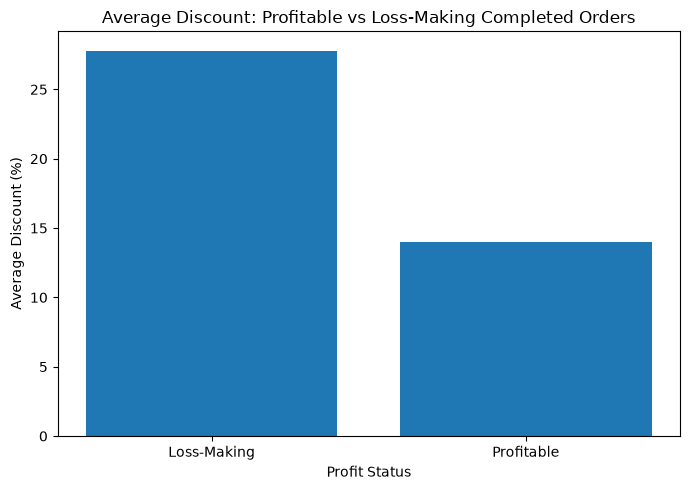

In [53]:
discount_comparison = (
    completed_orders.groupby("profit_status")["discount_pct"]
    .mean()
    .reset_index()
)

plt.figure(figsize=(7, 5))

plt.bar(
    discount_comparison["profit_status"],
    discount_comparison["discount_pct"]
)

plt.title("Average Discount: Profitable vs Loss-Making Completed Orders")
plt.xlabel("Profit Status")
plt.ylabel("Average Discount (%)")

plt.tight_layout()
plt.show()

## 5.12 Final EDA Summary & Export

The Python EDA phase analyzed the major drivers of revenue leakage and profitability across discounts, returns, cancellations, delivery performance, shipping costs, products, regions, customer segments, and time.

Key analytical tables are exported below for use in later stages of the project, including SQL validation, Excel analysis, and Power BI dashboard development.

Final quantified business insights will be documented after validating the outputs across the complete analysis workflow.

In [54]:
import os

eda_output_path = "../data/eda_outputs"

os.makedirs(eda_output_path, exist_ok=True)

print("EDA output folder ready:")
print(eda_output_path)

EDA output folder ready:
../data/eda_outputs


In [55]:
leakage_summary.to_csv(
    f"{eda_output_path}/leakage_by_reason.csv",
    index=False
)

regional_analysis.to_csv(
    f"{eda_output_path}/regional_analysis.csv",
    index=False
)

category_analysis.to_csv(
    f"{eda_output_path}/category_analysis.csv",
    index=False
)

subcategory_analysis.to_csv(
    f"{eda_output_path}/subcategory_analysis.csv",
    index=False
)

product_analysis.to_csv(
    f"{eda_output_path}/product_analysis.csv",
    index=False
)

segment_analysis.to_csv(
    f"{eda_output_path}/customer_segment_analysis.csv",
    index=False
)

monthly_analysis.to_csv(
    f"{eda_output_path}/monthly_analysis.csv",
    index=False
)

return_reason_analysis.to_csv(
    f"{eda_output_path}/return_reason_analysis.csv",
    index=False
)

completed_comparison.to_csv(
    f"{eda_output_path}/completed_order_profitability.csv",
    index=False
)

print("Main EDA tables exported successfully.")

Main EDA tables exported successfully.


In [56]:
loss_making_products.to_csv(
    f"{eda_output_path}/loss_making_products.csv",
    index=False
)

high_revenue_low_margin.to_csv(
    f"{eda_output_path}/high_revenue_low_margin_products.csv",
    index=False
)

highest_leakage_products.to_csv(
    f"{eda_output_path}/highest_leakage_products.csv",
    index=False
)

completed_loss_reasons.to_csv(
    f"{eda_output_path}/completed_loss_reasons.csv",
    index=False
)

completed_category_loss.to_csv(
    f"{eda_output_path}/completed_category_loss.csv",
    index=False
)

print("Risk analysis tables exported successfully.")

Risk analysis tables exported successfully.


In [57]:
exported_files = os.listdir(eda_output_path)

print("Total Exported Files:", len(exported_files))

for file in sorted(exported_files):
    print(file)

Total Exported Files: 14
category_analysis.csv
completed_category_loss.csv
completed_loss_reasons.csv
completed_order_profitability.csv
customer_segment_analysis.csv
high_revenue_low_margin_products.csv
highest_leakage_products.csv
leakage_by_reason.csv
loss_making_products.csv
monthly_analysis.csv
product_analysis.csv
regional_analysis.csv
return_reason_analysis.csv
subcategory_analysis.csv
